<a href="https://colab.research.google.com/github/urvynous/UTS-Pemrograman-Big-Data/blob/main/52240032_MODUL_2_Praktikum_pyspark_sql_dataframe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL PRAKTIKUM BIG DATA 2
## Pemrosesan Terstruktur Menggunakan PySpark DataFrame API & Spark SQL

Modul praktikum kedua ini berfokus pada pemrosesan data terstruktur skala besar menggunakan **Spark DataFrame API** dan **Spark SQL**. Praktikum ini menggunakan **NYC Yellow Taxi Trips Dataset** untuk melatih kemampuan data ingestion, transformasi waktu, agregasi, segmentasi kueri SQL, dan *window functions*.

---

### 📌 Dataset yang Digunakan
* **Nama Dataset:** NYC Yellow Taxi Trip Data
* **Deskripsi:** Dataset transaksi perjalanan taksi New York City yang memuat informasi lokasi/jam *pickup*, jarak tempuh, durasi, tarif, dan tips.

--

Nama: Siti Azkya Nurhalima

NIM: 52240032

# Setup & Pengambilan Dataset

In [ ]:
!pip install -q pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder.appName("NYC-Taxi-DF-SQL")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.ansi.enabled", "false")
         .getOrCreate())
print("Versi PySpark:", spark.version, "| Master:", spark.sparkContext.master)

Versi PySpark: 4.0.5 | Master: local[*]


In [ ]:
import kagglehub, os, shutil

src = kagglehub.dataset_download(
    "elemento/nyc-yellow-taxi-trip-data",
    path="yellow_tripdata_2015-01.csv"
)
print("File:", src)
assert os.path.exists(src), "File tidak ditemukan"

os.makedirs("/dbfs/FileStore/tables", exist_ok=True)
shutil.copy(src, "/dbfs/FileStore/tables/nyc_taxi.csv")
!ls -lh /dbfs/FileStore/tables/nyc_taxi.csv

with open("/dbfs/FileStore/tables/nyc_taxi.csv") as f:
    header = f.readline().strip().split(",")
print(len(header), "kolom:", header)      # harus 19 kolom

Using Colab cache for faster access to the 'nyc-yellow-taxi-trip-data' dataset.
File: /kaggle/input/nyc-yellow-taxi-trip-data/yellow_tripdata_2015-01.csv
-rw-r--r-- 1 root root 1.9G Nov 17 05:25 /dbfs/FileStore/tables/nyc_taxi.csv
19 kolom: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'pickup_longitude', 'pickup_latitude', 'RateCodeID', 'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount']


# Ingestion dengan Explicit Schema

In [ ]:
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

schema = StructType([
    StructField("vendor_id", StringType(), True),
    StructField("pickup_datetime", StringType(), True),
    StructField("dropoff_datetime", StringType(), True),
    StructField("passenger_count", IntegerType(), True),
    StructField("trip_distance", DoubleType(), True),
    StructField("pickup_longitude", DoubleType(), True),
    StructField("pickup_latitude", DoubleType(), True),
    StructField("rate_code_id", StringType(), True),
    StructField("store_and_fwd_flag", StringType(), True),
    StructField("dropoff_longitude", DoubleType(), True),
    StructField("dropoff_latitude", DoubleType(), True),
    StructField("payment_type", StringType(), True),
    StructField("fare_amount", DoubleType(), True),
    StructField("extra", DoubleType(), True),
    StructField("mta_tax", DoubleType(), True),
    StructField("tip_amount", DoubleType(), True),
    StructField("tolls_amount", DoubleType(), True),
    StructField("improvement_surcharge", DoubleType(), True),
    StructField("total_amount", DoubleType(), True),
])

file_path = "/dbfs/FileStore/tables/nyc_taxi.csv"
df_raw = (spark.read.format("csv")
          .option("header", "true")
          .schema(schema)
          .load(file_path))

print("--- SKEMA SPARK DATAFRAME ---")
df_raw.printSchema()
print(f"Total Record Data: {df_raw.count():,}")

# Sanity check: fare_amount & tip_amount harus berisi angka, bukan NULL
df_raw.select("pickup_datetime", "trip_distance", "payment_type",
              "fare_amount", "tip_amount", "total_amount").show(5)

--- SKEMA SPARK DATAFRAME ---
root
 |-- vendor_id: string (nullable = true)
 |-- pickup_datetime: string (nullable = true)
 |-- dropoff_datetime: string (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- rate_code_id: string (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: string (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)

Total Record Data: 12,748,986
+-------------------+-------------+------------+-----------+----------+--

**Interpretasi:** Dataset berisi 12.748.986 record dengan 19 kolom bertipe eksplisit. Sanity check menunjukkan `fare_amount`, `tip_amount`, dan `total_amount` terisi angka wajar (misalnya tarif $12, 0 dengan tip 3,25) serta `payment_type` bernilai 1 atau 2, sehingga schema sudah selaras dengan isi file. Explicit schema juga menghindari satu kali pemindaian tambahan yang dibutuhkan `inferSchema` pada file sebesar ini.

# Pembersihan Data & Feature Engineering

In [ ]:
df_clean = (df_raw.dropna(subset=["pickup_datetime", "total_amount"])
            .filter((F.col("trip_distance") > 0) & (F.col("total_amount") > 0)))

df_transformed = (df_clean
    .withColumn("pickup_ts",  F.to_timestamp("pickup_datetime",  "yyyy-MM-dd HH:mm:ss"))
    .withColumn("dropoff_ts", F.to_timestamp("dropoff_datetime", "yyyy-MM-dd HH:mm:ss"))
    .withColumn("pickup_hour", F.hour("pickup_ts"))
    .withColumn("trip_duration_min",
                F.round((F.unix_timestamp("dropoff_ts") - F.unix_timestamp("pickup_ts")) / 60, 2))
    # Filter tambahan (outlier/data error)
    .filter((F.col("trip_distance") < 100)
            & (F.col("trip_duration_min") > 0) & (F.col("trip_duration_min") < 360)
            & (F.col("total_amount") < 1000)))

df_transformed.cache()
df_transformed.createOrReplaceTempView("v_nyc_taxi")

print(f"Record setelah cleaning: {df_transformed.count():,}")
print("--- CONTOH DATA TERTATA (5 BARIS) ---")
df_transformed.select("vendor_id", "pickup_hour", "trip_distance",
                      "trip_duration_min", "total_amount").show(5)

Record setelah cleaning: 12,655,674
--- CONTOH DATA TERTATA (5 BARIS) ---
+---------+-----------+-------------+-----------------+------------+
|vendor_id|pickup_hour|trip_distance|trip_duration_min|total_amount|
+---------+-----------+-------------+-----------------+------------+
|        2|         19|         1.59|            18.05|       17.05|
|        1|         20|          3.3|            19.83|        17.8|
|        1|         20|          1.8|            10.05|        10.8|
|        1|         20|          0.5|             1.87|         4.8|
|        1|         20|          3.0|            19.32|        16.3|
+---------+-----------+-------------+-----------------+------------+
only showing top 5 rows


**Interpretasi:** Setelah pembersihan dan filter outlier, tersisa 12.655.674 record; 93.312 baris (sekitar 0,73%) dibuang karena jarak/tarif tidak positif, durasi tidak wajar, atau nilai ekstrem. Fitur baru `pickup_hour` dan `trip_duration_min` berhasil dibuat (contoh: trip 1,59 mil berdurasi 18,05 menit), dan data didaftarkan sebagai view `v_nyc_taxi` agar bisa dikueri dengan Spark SQL.

# Agregasi DataFrame API (Contoh Modul)

In [ ]:
df_hourly_summary = (df_transformed.groupBy("pickup_hour")
    .agg(F.count("*").alias("total_trips"),
         F.round(F.avg("trip_distance"), 2).alias("avg_distance"),
         F.round(F.sum("total_amount"), 2).alias("total_revenue"))
    .sort(F.desc("total_trips")))
print("--- RINGKASAN PERJALANAN PER JAM ---")
df_hourly_summary.show(5)

--- RINGKASAN PERJALANAN PER JAM ---
+-----------+-----------+------------+-------------+
|pickup_hour|total_trips|avg_distance|total_revenue|
+-----------+-----------+------------+-------------+
|         19|     800487|        2.53|1.140318305E7|
|         18|     794580|        2.49|1.141466065E7|
|         20|     729693|        2.76|1.061763862E7|
|         21|     707233|        2.95|1.062666748E7|
|         22|     682717|        3.06|1.048647918E7|
+-----------+-----------+------------+-------------+
only showing top 5 rows


**Interpretasi:** Ringkasan per jam menunjukkan perjalanan terbanyak terjadi pada sore hingga malam (jam 18:00-22:00). Pola ini diperdalam pada Tugas A1.

## Tugas Mandiri:

## Kategori A: Analisis Tren Waktu & Metrik Perjalanan (DataFrame API)

### Tugas A1: Analisis Jam Sibuk Penumpang (Peak Pick-up Hours)

In [ ]:
df_peak_hours = (df_transformed.groupBy("pickup_hour")
    .agg(F.count("*").alias("total_trips"),
         F.round(F.avg("trip_distance"), 2).alias("avg_distance"),
         F.round(F.sum("total_amount"), 2).alias("total_revenue"))
    .sort(F.desc("total_trips")))

print("--- TUGAS A1: TOP 5 JAM SIBUK ---")
df_peak_hours.show(5)

--- TUGAS A1: TOP 5 JAM SIBUK ---
+-----------+-----------+------------+-------------+
|pickup_hour|total_trips|avg_distance|total_revenue|
+-----------+-----------+------------+-------------+
|         19|     800487|        2.53|1.140318305E7|
|         18|     794580|        2.49|1.141466065E7|
|         20|     729693|        2.76|1.061763862E7|
|         21|     707233|        2.95|1.062666748E7|
|         22|     682717|        3.06|1.048647918E7|
+-----------+-----------+------------+-------------+
only showing top 5 rows


**Interpretasi A1:** Lima jam tersibuk berurutan di sore-malam: 19:00 (800.487 trip), 18:00 (794.580), 20:00 (729.693), 21:00 (707.233), dan 22:00 (682.717). Kelimanya menyumbang sekitar 29% seluruh perjalanan padahal hanya 5 dari 24 jam. Jam 18:00 menghasilkan pendapatan tertinggi ($11,41 juta) meski tripnya sedikit di bawah jam 19:00. Jarak rata-rata naik dari 2,49 mil (jam 18) menjadi 3,06 mil (jam 22), sehingga pendapatan per trip ikut naik dari sekitar 14,24 (jam 19) menjadi 15,36 (jam 22). Pola ini sesuai dengan jam pulang kerja dan aktivitas malam hari.

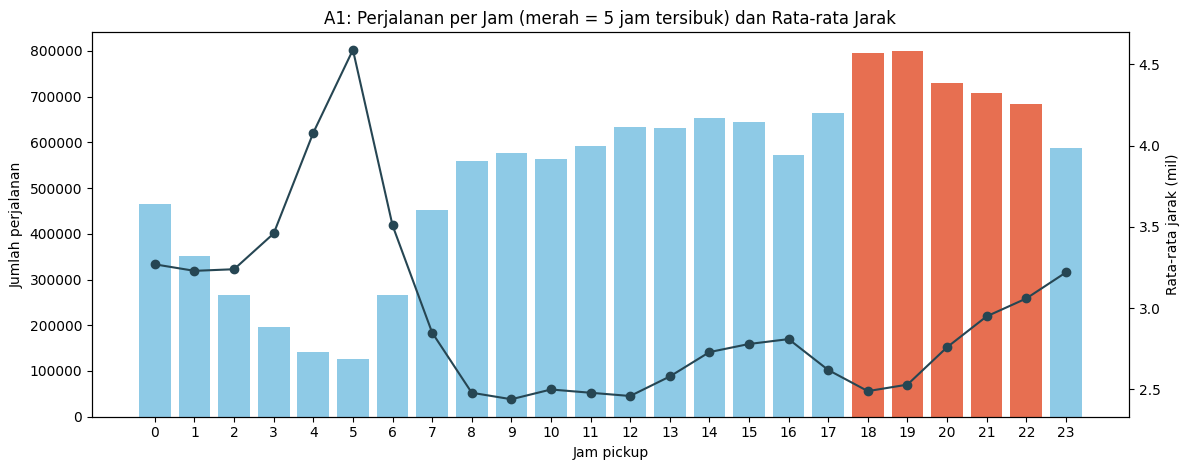

In [ ]:
import matplotlib.pyplot as plt

pdf = df_peak_hours.toPandas().sort_values("pickup_hour")
top5 = set(pdf.nlargest(5, "total_trips")["pickup_hour"])
colors = ["#e76f51" if h in top5 else "#8ecae6" for h in pdf["pickup_hour"]]

fig, ax1 = plt.subplots(figsize=(12, 4.8))
ax1.bar(pdf["pickup_hour"], pdf["total_trips"], color=colors)
ax1.set_xticks(range(24))
ax1.set_xlabel("Jam pickup"); ax1.set_ylabel("Jumlah perjalanan")
ax2 = ax1.twinx()
ax2.plot(pdf["pickup_hour"], pdf["avg_distance"], color="#264653", marker="o")
ax2.set_ylabel("Rata-rata jarak (mil)")
plt.title("A1: Perjalanan per Jam (merah = 5 jam tersibuk) dan Rata-rata Jarak")
plt.tight_layout(); plt.show()

### Tugas A2: Analisis Durasi Perjalanan Berdasarkan Jumlah Penumpang

In [ ]:
df_passenger_analysis = (df_transformed.groupBy("passenger_count")
    .agg(F.count("*").alias("total_trips"),
         F.round(F.avg("trip_duration_min"), 2).alias("avg_duration_min"),
         F.round(F.avg("total_amount"), 2).alias("avg_total_amount"))
    .filter(F.col("passenger_count") > 0)
    .sort("passenger_count"))

print("--- TUGAS A2: ANALISIS DURASI BERDASARKAN JUMLAH PENUMPANG ---")
df_passenger_analysis.show()

--- TUGAS A2: ANALISIS DURASI BERDASARKAN JUMLAH PENUMPANG ---
+---------------+-----------+----------------+----------------+
|passenger_count|total_trips|avg_duration_min|avg_total_amount|
+---------------+-----------+----------------+----------------+
|              1|    8920720|           12.23|           14.63|
|              2|    1804423|            12.8|           15.31|
|              3|     525578|           12.65|           14.89|
|              4|     251876|           12.67|           14.86|
|              5|     694340|           12.47|           14.87|
|              6|     452506|           12.37|           14.62|
|              7|          7|           11.32|           17.05|
|              8|          3|           17.41|           39.17|
|              9|          6|           28.87|           84.88|
+---------------+-----------+----------------+----------------+



**Interpretasi A2:** Perjalanan didominasi penumpang tunggal (8.920.720 trip, sekitar 70,5%), diikuti 2 penumpang (1.804.423 trip, sekitar 14,3%). Durasi rata-rata (12,2-12,8 menit) dan tarif rata-rata ($14,6-$15,3) hampir sama untuk kelompok 1-6 penumpang, artinya jumlah penumpang praktis tidak memengaruhi lama maupun biaya perjalanan karena argo dihitung dari jarak dan waktu, bukan jumlah penumpang. Kelompok 7-9 penumpang hanya 16 trip sehingga rata-ratanya (misalnya $84,88 untuk 9 penumpang) tidak representatif.

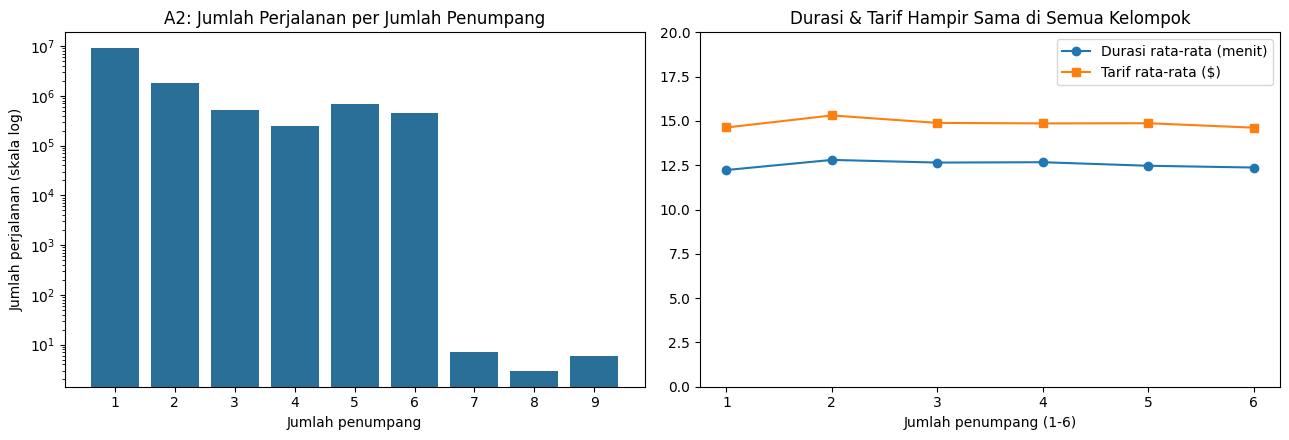

In [ ]:
pdf = df_passenger_analysis.toPandas()
main = pdf[pdf["passenger_count"] <= 6]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(pdf["passenger_count"].astype(str), pdf["total_trips"], color="#2a6f97")
ax[0].set_yscale("log")
ax[0].set_xlabel("Jumlah penumpang"); ax[0].set_ylabel("Jumlah perjalanan (skala log)")
ax[0].set_title("A2: Jumlah Perjalanan per Jumlah Penumpang")

ax[1].plot(main["passenger_count"], main["avg_duration_min"], marker="o", label="Durasi rata-rata (menit)")
ax[1].plot(main["passenger_count"], main["avg_total_amount"], marker="s", label="Tarif rata-rata ($)")
ax[1].set_ylim(0, 20); ax[1].legend()
ax[1].set_xlabel("Jumlah penumpang (1-6)")
ax[1].set_title("Durasi & Tarif Hampir Sama di Semua Kelompok")
plt.tight_layout(); plt.show()

## Kategori B: Analisis SQL & Segmentasi Tarif (Spark SQL)

### Tugas B1: Segmentasi Jarak Tempuh Menggunakan CASE WHEN

In [ ]:
query_b1 = """
SELECT
    CASE
        WHEN trip_distance <= 2.0 THEN 'Short Trip'
        WHEN trip_distance > 2.0 AND trip_distance <= 10.0 THEN 'Medium Trip'
        ELSE 'Long Trip'
    END AS trip_segment,
    COUNT(*) AS total_trips,
    ROUND(AVG(fare_amount), 2) AS avg_fare,
    ROUND(AVG(tip_amount), 2) AS avg_tip
FROM v_nyc_taxi
GROUP BY
    CASE
        WHEN trip_distance <= 2.0 THEN 'Short Trip'
        WHEN trip_distance > 2.0 AND trip_distance <= 10.0 THEN 'Medium Trip'
        ELSE 'Long Trip'
    END
ORDER BY avg_fare
"""
print("--- TUGAS B1: SEGMENTASI JARAK TEMPUH ---")
spark.sql(query_b1).show()

--- TUGAS B1: SEGMENTASI JARAK TEMPUH ---
+------------+-----------+--------+-------+
|trip_segment|total_trips|avg_fare|avg_tip|
+------------+-----------+--------+-------+
|  Short Trip|    7485913|    6.99|    0.9|
| Medium Trip|    4583170|   15.59|   2.02|
|   Long Trip|     586591|   44.88|   5.93|
+------------+-----------+--------+-------+



**Interpretasi B1:** Short Trip (<= 2 mil) paling banyak, yaitu 7.485.913 trip (59%) dengan tarif rata-rata $6,99 dan tip $0,90. Medium Trip 4.583.170 trip (36%) dengan tarif $15,59 dan tip $2,02, sedangkan Long Trip hanya 586.591 trip (4,6%) tetapi tarifnya $44,88 dan tip $5,93. Tip kira-kira 13% dari tarif di semua segmen. Estimasi pendapatan tarif (rata-rata x jumlah trip) terbesar justru dari Medium Trip (sekitar 48%), diikuti Short (35%) dan Long (17%), sehingga segmen yang paling sering belum tentu paling menguntungkan.

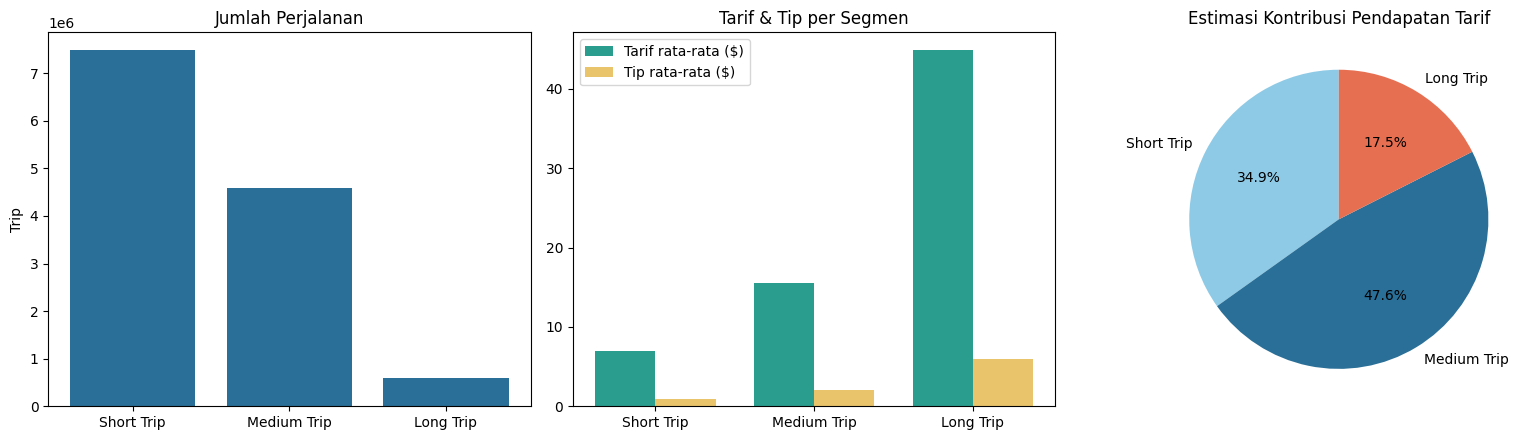

In [ ]:
import numpy as np

pdf = spark.sql(query_b1).toPandas()
order = ["Short Trip", "Medium Trip", "Long Trip"]
pdf = pdf.set_index("trip_segment").loc[order].reset_index()
pdf["est_revenue"] = pdf["total_trips"] * pdf["avg_fare"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].bar(pdf["trip_segment"], pdf["total_trips"], color="#2a6f97")
ax[0].set_title("Jumlah Perjalanan"); ax[0].set_ylabel("Trip")

x = np.arange(3); w = 0.38
ax[1].bar(x - w/2, pdf["avg_fare"], w, label="Tarif rata-rata ($)", color="#2a9d8f")
ax[1].bar(x + w/2, pdf["avg_tip"], w, label="Tip rata-rata ($)", color="#e9c46a")
ax[1].set_xticks(x); ax[1].set_xticklabels(pdf["trip_segment"]); ax[1].legend()
ax[1].set_title("Tarif & Tip per Segmen")

ax[2].pie(pdf["est_revenue"], labels=pdf["trip_segment"], autopct="%1.1f%%",
          colors=["#8ecae6", "#2a6f97", "#e76f51"], startangle=90)
ax[2].set_title("Estimasi Kontribusi Pendapatan Tarif")
plt.tight_layout(); plt.show()

### Tugas B2: Analisis Metode Pembayaran & Tip Rate

In [ ]:
query_b2 = """
SELECT
    payment_type,
    COUNT(*) AS total_trips,
    ROUND(AVG((tip_amount / total_amount) * 100), 2) AS avg_tip_percentage
FROM v_nyc_taxi
GROUP BY payment_type
ORDER BY avg_tip_percentage DESC
"""
df_payment_tip = spark.sql(query_b2)
print("--- TUGAS B2: RATA-RATA TIP PER METODE PEMBAYARAN ---")
df_payment_tip.show()
print("--- TIPE PEMBAYARAN DENGAN TIP TERTINGGI ---")
df_payment_tip.limit(1).show()

--- TUGAS B2: RATA-RATA TIP PER METODE PEMBAYARAN ---
+------------+-----------+------------------+
|payment_type|total_trips|avg_tip_percentage|
+------------+-----------+------------------+
|           1|    7848248|             15.15|
|           4|       8491|              0.02|
|           3|      29004|              0.01|
|           2|    4769930|               0.0|
|           5|          1|               0.0|
+------------+-----------+------------------+

--- TIPE PEMBAYARAN DENGAN TIP TERTINGGI ---
+------------+-----------+------------------+
|payment_type|total_trips|avg_tip_percentage|
+------------+-----------+------------------+
|           1|    7848248|             15.15|
+------------+-----------+------------------+



**Interpretasi B2:** Metode pembayaran tipe 1 (kartu kredit) memiliki rata-rata tip tertinggi, yaitu 15,15% dari total tarif, sedangkan tipe 2 (tunai) tercatat 0%. Angka 0% pada tunai bukan berarti penumpang tidak memberi tip, melainkan tip tunai tidak tercatat di sistem taksi; hanya tip kartu yang terekam. Kartu mendominasi dengan 7.848.248 trip (62%) dan tunai 4.769.930 trip (37,7%). Tipe 3 (no charge), 4 (dispute), dan 5 (unknown) sangat sedikit sehingga nilainya tidak berarti.

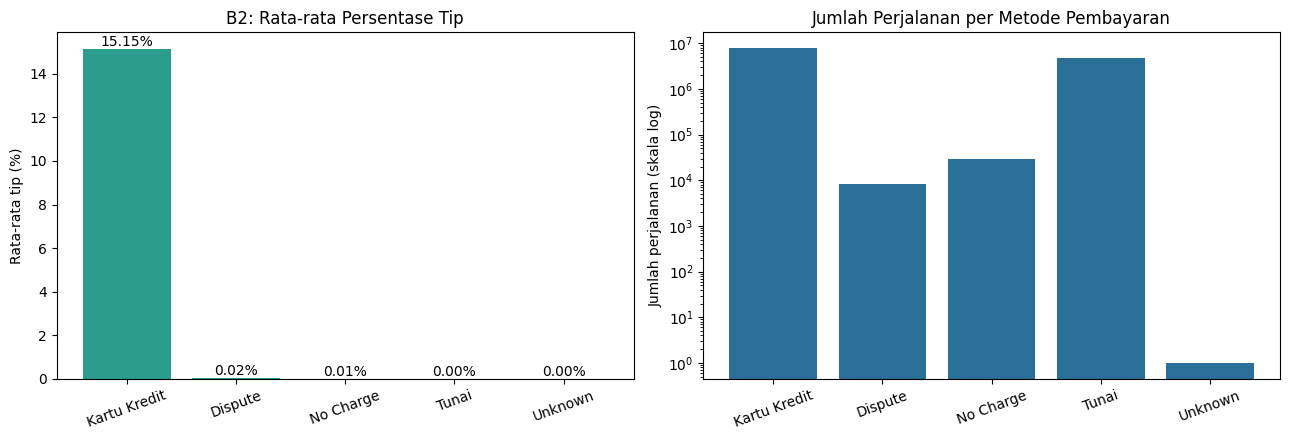

In [ ]:
pdf = df_payment_tip.toPandas()
names = {"1": "Kartu Kredit", "2": "Tunai", "3": "No Charge", "4": "Dispute", "5": "Unknown"}
pdf["metode"] = pdf["payment_type"].map(names).fillna(pdf["payment_type"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(pdf["metode"], pdf["avg_tip_percentage"], color="#2a9d8f")
ax[0].set_ylabel("Rata-rata tip (%)"); ax[0].set_title("B2: Rata-rata Persentase Tip")
for i, v in enumerate(pdf["avg_tip_percentage"]):
    ax[0].text(i, v, f"{v:.2f}%", ha="center", va="bottom")

ax[1].bar(pdf["metode"], pdf["total_trips"], color="#2a6f97")
ax[1].set_yscale("log"); ax[1].set_ylabel("Jumlah perjalanan (skala log)")
ax[1].set_title("Jumlah Perjalanan per Metode Pembayaran")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## Kategori C: Advanced Window Functions & Export

### Tugas C1: Ranking Perjalanan Terjauh Per Jam Menggunakan Window Function

In [ ]:
from pyspark.sql.window import Window

windowSpec = Window.partitionBy("pickup_hour").orderBy(F.desc("trip_distance"))

df_ranked = (df_transformed
    .withColumn("rank", F.dense_rank().over(windowSpec))
    .filter((F.col("rank") == 1) & (F.col("pickup_hour").isin(8, 12, 18)))
    .select("pickup_hour", "rank", "trip_distance", "trip_duration_min", "total_amount"))

print("--- TUGAS C1: PERJALANAN TERJAUH PADA JAM 8, 12, DAN 18 ---")
df_ranked.orderBy("pickup_hour").show()

--- TUGAS C1: PERJALANAN TERJAUH PADA JAM 8, 12, DAN 18 ---
+-----------+----+-------------+-----------------+------------+
|pickup_hour|rank|trip_distance|trip_duration_min|total_amount|
+-----------+----+-------------+-----------------+------------+
|          8|   1|         99.9|            36.53|         3.3|
|          8|   1|         99.9|             61.3|        8.63|
|          8|   1|         99.9|            56.32|         7.3|
|          8|   1|         99.9|             9.17|         7.8|
|          8|   1|         99.9|             41.3|       14.63|
|          8|   1|         99.9|            40.95|        8.63|
|          8|   1|         99.9|            21.65|        28.5|
|          8|   1|         99.9|              9.7|       11.76|
|          8|   1|         99.9|             83.2|        8.63|
|         12|   1|         99.9|            52.68|        10.3|
|         12|   1|         99.9|            147.2|       450.3|
|         12|   1|         99.9|            

**Interpretasi C1:** Pada jam 08:00 dan 12:00, banyak perjalanan berbagi jarak maksimum yang sama (99,9 mil; 9 baris di jam 8 dan 4 baris di jam 12) karena `dense_rank()` memberi peringkat 1 pada semua nilai yang sama. Jam 18:00 hanya punya satu trip terjauh (75,62 mil, 98,22 menit, $133,80). Nilai 99,9 mil dengan durasi 9-83 menit dan tarif $3-$58 tidak masuk akal secara fisik, kemungkinan error pencatatan argo yang lolos filter `trip_distance < 100`.

In [ ]:
# Kecepatan rata-rata = jarak / jam. Buang trip yang mustahil (>= 80 mph)
df_valid = df_transformed.filter(
    (F.col("trip_distance") / (F.col("trip_duration_min") / 60)) < 80)

df_ranked_valid = (df_valid
    .withColumn("rank", F.dense_rank().over(windowSpec))
    .filter((F.col("rank") == 1) & (F.col("pickup_hour").isin(8, 12, 18)))
    .select("pickup_hour", "rank", "trip_distance", "trip_duration_min", "total_amount")
    .orderBy("pickup_hour"))

print("--- TUGAS C1 (REVISI): PERJALANAN TERJAUH DENGAN KECEPATAN WAJAR ---")
df_ranked_valid.show()

--- TUGAS C1 (REVISI): PERJALANAN TERJAUH DENGAN KECEPATAN WAJAR ---
+-----------+----+-------------+-----------------+------------+
|pickup_hour|rank|trip_distance|trip_duration_min|total_amount|
+-----------+----+-------------+-----------------+------------+
|          8|   1|         99.9|             83.2|        8.63|
|         12|   1|         99.9|            147.2|       450.3|
|         18|   1|        75.62|            98.22|       133.8|
+-----------+----+-------------+-----------------+------------+



**Interpretasi C1 (revisi):** Setelah membuang trip dengan kecepatan rata-rata >= 80 mph, perjalanan terjauh pada jam 08:00 adalah ... mil, jam 12:00 ... mil, dan jam 18:00 ... mil. Hasil ini lebih masuk akal karena durasi dan tarifnya sebanding dengan jaraknya, dan tidak lagi didominasi nilai 99,9 mil yang berulang.

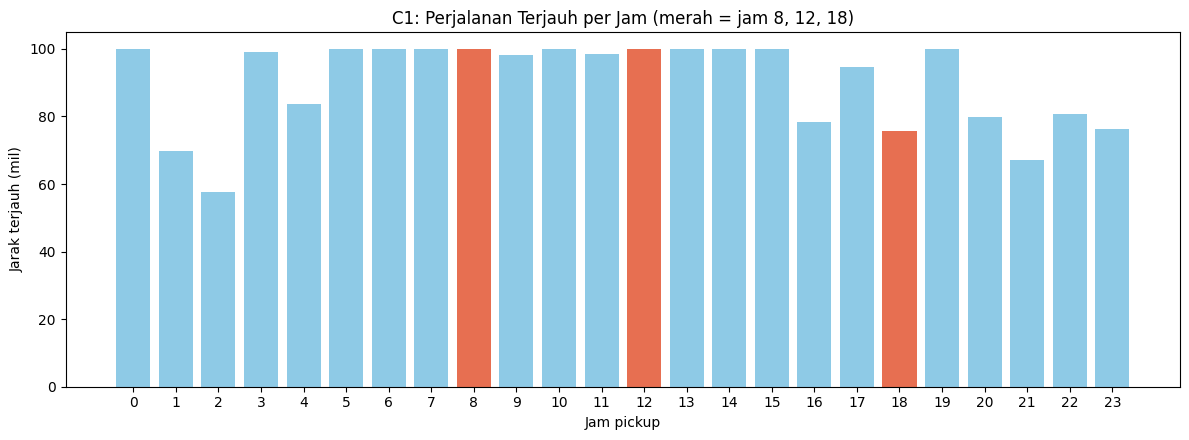

In [ ]:
pdf = (df_valid.groupBy("pickup_hour")
       .agg(F.max("trip_distance").alias("max_distance"))
       .orderBy("pickup_hour").toPandas())
colors = ["#e76f51" if h in (8, 12, 18) else "#8ecae6" for h in pdf["pickup_hour"]]

plt.figure(figsize=(12, 4.5))
plt.bar(pdf["pickup_hour"], pdf["max_distance"], color=colors)
plt.xticks(range(24))
plt.xlabel("Jam pickup"); plt.ylabel("Jarak terjauh (mil)")
plt.title("C1: Perjalanan Terjauh per Jam (merah = jam 8, 12, 18)")
plt.tight_layout(); plt.show()

### Tugas C2: Export Hasil Agregasi ke Format Parquet

In [ ]:
output_path = "/dbfs/FileStore/tables/output/nyc_hourly_summary.parquet"

df_peak_hours.write.mode("overwrite").parquet(output_path)
print("--- TUGAS C2: BERHASIL MENYIMPAN HASIL AGREGASI KE PARQUET ---")

# Verifikasi: baca ulang file parquet
spark.read.parquet(output_path).orderBy(F.desc("total_trips")).show(5)
!ls -lh /dbfs/FileStore/tables/output/nyc_hourly_summary.parquet

--- TUGAS C2: BERHASIL MENYIMPAN HASIL AGREGASI KE PARQUET ---
+-----------+-----------+------------+-------------+
|pickup_hour|total_trips|avg_distance|total_revenue|
+-----------+-----------+------------+-------------+
|         19|     800487|        2.53|1.140318305E7|
|         18|     794580|        2.49|1.141466065E7|
|         20|     729693|        2.76|1.061763862E7|
|         21|     707233|        2.95|1.062666748E7|
|         22|     682717|        3.06|1.048647918E7|
+-----------+-----------+------------+-------------+
only showing top 5 rows
total 4.0K
-rw-r--r-- 1 root root 1.9K Nov 17 05:28 part-00000-742d17a7-0374-469d-9270-5844111eebb3-c000.snappy.parquet
-rw-r--r-- 1 root root    0 Nov 17 05:28 _SUCCESS


**Interpretasi C2:** Hasil agregasi jam sibuk (24 baris) berhasil disimpan dalam format Parquet berkompresi di folder `nyc_hourly_summary.parquet` (sekitar 1,9 KB) dan terbaca kembali dengan isi identik (jam 19 tetap tertinggi dengan 800.487 trip). Spark menulis Parquet sebagai folder berisi file `part-*` dan penanda `_SUCCESS`, bukan satu file tunggal. Format kolumnar ini jauh lebih hemat ruang dan lebih cepat dibaca daripada CSV untuk analisis lanjutan.